In [4]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import joblib

from sklearn.model_selection import train_test_split
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.pipeline import Pipeline
from sklearn.linear_model import Ridge
from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import root_mean_squared_error, mean_absolute_error, r2_score

# Ignore minor warnings for clean notebook output
import warnings
warnings.filterwarnings('ignore')

In [5]:
df = pd.read_csv("Clean_Dataset.csv")

In [6]:
df

,Unnamed: 0,airline,flight,source_city,departure_time,stops,arrival_time,destination_city,class,duration,days_left,price
0,0,SpiceJet,SG-8709,Delhi,Evening,zero,Night,Mumbai,Economy,2.17,1,5953
1,1,SpiceJet,SG-8157,Delhi,Early_Morning,zero,Morning,Mumbai,Economy,2.33,1,5953
2,2,AirAsia,I5-764,Delhi,Early_Morning,zero,Early_Morning,Mumbai,Economy,2.17,1,5956
3,3,Vistara,UK-995,Delhi,Morning,zero,Afternoon,Mumbai,Economy,2.25,1,5955
4,4,Vistara,UK-963,Delhi,Morning,zero,Morning,Mumbai,Economy,2.33,1,5955
...,...,...,...,...,...,...,...,...,...,...,...,...
300148,300148,Vistara,UK-822,Chennai,Morning,one,Evening,Hyderabad,Business,10.08,49,69265
300149,300149,Vistara,UK-826,Chennai,Afternoon,one,Night,Hyderabad,Business,10.42,49,77105
300150,300150,Vistara,UK-832,Chennai,Early_Morning,one,Night,Hyderabad,Business,13.83,49,79099
300151,300151,Vistara,UK-828,Chennai,Early_Morning,one,Evening,Hyderabad,Business,10.00,49,81585


In [7]:
df.drop(columns=['Unnamed: 0', 'flight'], inplace=True)
df.head()

,airline,source_city,departure_time,stops,arrival_time,destination_city,class,duration,days_left,price
0,SpiceJet,Delhi,Evening,zero,Night,Mumbai,Economy,2.17,1,5953
1,SpiceJet,Delhi,Early_Morning,zero,Morning,Mumbai,Economy,2.33,1,5953
2,AirAsia,Delhi,Early_Morning,zero,Early_Morning,Mumbai,Economy,2.17,1,5956
3,Vistara,Delhi,Morning,zero,Afternoon,Mumbai,Economy,2.25,1,5955
4,Vistara,Delhi,Morning,zero,Morning,Mumbai,Economy,2.33,1,5955


In [8]:
df['duration_mins'] = (df['duration'] * 60).round().astype(int) #converting the duration column from hours to minutes
df.head()

,airline,source_city,departure_time,stops,arrival_time,destination_city,class,duration,days_left,price,duration_mins
0,SpiceJet,Delhi,Evening,zero,Night,Mumbai,Economy,2.17,1,5953,130
1,SpiceJet,Delhi,Early_Morning,zero,Morning,Mumbai,Economy,2.33,1,5953,140
2,AirAsia,Delhi,Early_Morning,zero,Early_Morning,Mumbai,Economy,2.17,1,5956,130
3,Vistara,Delhi,Morning,zero,Afternoon,Mumbai,Economy,2.25,1,5955,135
4,Vistara,Delhi,Morning,zero,Morning,Mumbai,Economy,2.33,1,5955,140


In [9]:
df.drop(columns=['duration'], inplace=True) #Removing the original duration column as we have created a new column for duration in minutes
df.head()

,airline,source_city,departure_time,stops,arrival_time,destination_city,class,days_left,price,duration_mins
0,SpiceJet,Delhi,Evening,zero,Night,Mumbai,Economy,1,5953,130
1,SpiceJet,Delhi,Early_Morning,zero,Morning,Mumbai,Economy,1,5953,140
2,AirAsia,Delhi,Early_Morning,zero,Early_Morning,Mumbai,Economy,1,5956,130
3,Vistara,Delhi,Morning,zero,Afternoon,Mumbai,Economy,1,5955,135
4,Vistara,Delhi,Morning,zero,Morning,Mumbai,Economy,1,5955,140


In [10]:
stops_map = {'zero': 0, 'one': 1, 'two_or_more': 2} #creating dictionary that assigns normal numbers so that i can convert the text into numbers
df['stops_num'] = df['stops'].map(stops_map)
df.head()

,airline,source_city,departure_time,stops,arrival_time,destination_city,class,days_left,price,duration_mins,stops_num
0,SpiceJet,Delhi,Evening,zero,Night,Mumbai,Economy,1,5953,130,0
1,SpiceJet,Delhi,Early_Morning,zero,Morning,Mumbai,Economy,1,5953,140,0
2,AirAsia,Delhi,Early_Morning,zero,Early_Morning,Mumbai,Economy,1,5956,130,0
3,Vistara,Delhi,Morning,zero,Afternoon,Mumbai,Economy,1,5955,135,0
4,Vistara,Delhi,Morning,zero,Morning,Mumbai,Economy,1,5955,140,0


In [11]:
df.drop(columns=['stops'], inplace=True) #deleting the original stops column as we have created a new column for stops in numbers
df.head()

,airline,source_city,departure_time,arrival_time,destination_city,class,days_left,price,duration_mins,stops_num
0,SpiceJet,Delhi,Evening,Night,Mumbai,Economy,1,5953,130,0
1,SpiceJet,Delhi,Early_Morning,Morning,Mumbai,Economy,1,5953,140,0
2,AirAsia,Delhi,Early_Morning,Early_Morning,Mumbai,Economy,1,5956,130,0
3,Vistara,Delhi,Morning,Afternoon,Mumbai,Economy,1,5955,135,0
4,Vistara,Delhi,Morning,Morning,Mumbai,Economy,1,5955,140,0


In [12]:
df.sample(n=5)

,airline,source_city,departure_time,arrival_time,destination_city,class,days_left,price,duration_mins,stops_num
105425,SpiceJet,Bangalore,Early_Morning,Night,Kolkata,Economy,21,4814,940,1
63683,Indigo,Mumbai,Evening,Night,Kolkata,Economy,14,11088,335,1
293677,Vistara,Chennai,Evening,Evening,Bangalore,Business,7,60260,1430,1
128923,Indigo,Kolkata,Early_Morning,Evening,Mumbai,Economy,12,7802,550,1
5290,Vistara,Delhi,Evening,Night,Mumbai,Economy,27,7575,360,1


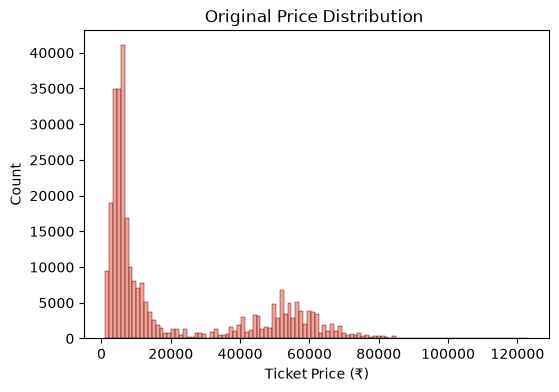

In [13]:
plt.figure(figsize=(6, 4))
sns.histplot(df['price'], color='salmon')
plt.title(f"Original Price Distribution ")
plt.xlabel("Ticket Price (₹)")
plt.show()

In [14]:
X = df.drop(columns=['price'])
y = df['price']

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

print("Training rows:", X_train.shape[0])
print("Testing rows :", X_test.shape[0])

Training rows: 240122
Testing rows : 60031


In [15]:
X_train_encoded = pd.get_dummies(X_train, drop_first=True) #getting dummies for the categorical variables in the training set and dropping the first column to avoid multicollinearity
X_test_encoded = pd.get_dummies(X_test, drop_first=True) #getting dummies for the categorical variables in the testing set and dropping the first column to avoid multicollinearity

X_train_encoded, X_test_encoded = X_train_encoded.align(X_test_encoded, join='left', axis=1, fill_value=0) # Ensure X_train_encoded and X_test_encoded have the exact same columns in the same order
 
print("Old number of columns:", X_train.shape[1])
print("New number of columns:", X_train_encoded.shape[1])

Old number of columns: 9
New number of columns: 29


In [16]:
# 1. Create the model using default basic settings
model = RandomForestRegressor()

# 2. Train the model on our training data
model.fit(X_train_encoded, y_train)

# 3. Predict ticket prices on the test data
predictions = model.predict(X_test_encoded)

# 4. Check the average error in Rupees
error = mean_absolute_error(y_test, predictions)
print("Average Error in Rupees:", round(error, 2))

Average Error in Rupees: 1085.02


In [17]:
# 1. Create a sample flight search (just like a user on your website)
sample_flight = pd.DataFrame([{
    'airline': 'Indigo',
    'source_city': 'Delhi',
    'departure_time': 'Morning',
    'arrival_time': 'Evening',
    'destination_city': 'Mumbai',
    'class': 'Economy',
    'days_left': 1,
    'duration_mins': 60,
    'stops_num': 1
}])

# 2. Convert text to 0s and 1s and match the 29 training columns
sample_encoded = pd.get_dummies(sample_flight)
sample_encoded = sample_encoded.reindex(columns=X_train_encoded.columns, fill_value=0)

# 3. Predict the ticket price
predicted_price = model.predict(sample_encoded)[0]
print("Predicted Ticket Price: ₹", round(predicted_price, 2))

Predicted Ticket Price: ₹ 8506.03


In [19]:
import joblib
import pandas as pd
from sklearn.metrics import r2_score, mean_absolute_error, root_mean_squared_error, mean_absolute_percentage_error

# Load your already-trained model and exact 29 feature columns
saved_model = joblib.load("../backend/aerofare_model.joblib")
model_cols = joblib.load("../backend/model_columns.joblib")

# Encode X_test to match the exact 29 columns the model expects
X_test_encoded = pd.get_dummies(X_test).reindex(columns=model_cols, fill_value=0)

# Predict on the 20% unseen holdout test set
y_pred = saved_model.predict(X_test_encoded)

r2 = r2_score(y_test, y_pred)
mae = mean_absolute_error(y_test, y_pred)
rmse = root_mean_squared_error(y_test, y_pred)
mape = mean_absolute_percentage_error(y_test, y_pred) * 100
approx_accuracy = 100 - mape

print(f"R² Score (Variance Accuracy) : {r2:.4f} ({r2*100:.2f}%)")
print(f"Mean Absolute Error (MAE)    : ₹{mae:,.2f}")
print(f"Root Mean Squared Error      : ₹{rmse:,.2f}")
print(f"Mean Abs. Percentage Error   : {mape:.2f}%")
print(f"Approx. Percentage Accuracy  : {approx_accuracy:.2f}%")

R² Score (Variance Accuracy) : 0.9848 (98.48%)
Mean Absolute Error (MAE)    : ₹1,087.22
Root Mean Squared Error      : ₹2,799.35
Mean Abs. Percentage Error   : 7.08%
Approx. Percentage Accuracy  : 92.92%
